# The trainability of photonic quantum circuits — a reproduction walkthrough

Makarovskiy, Taylor, Li, Hanks, Clark, Kim, Walmsley, Clements,
[arXiv:2607.21544](https://arxiv.org/abs/2607.21544) (2026).

This notebook is the entry point to the reproduction. It presents the paper as a scientific argument:
what is claimed, how it is tested, what evidence supports or weakens each claim, and what the verdict is.

**How to read the labels.** Every result is tagged:

- **[live, exact]** — computed in this notebook with exact rational arithmetic (no randomness, no seeds);
- **[live, Monte Carlo]** — computed here from seeded Haar samples, with standard errors;
- **[stored]** — loaded from a completed, logging-validated run (curated tables in `results/`, provenance in
  `results/PROVENANCE.md`), because it takes minutes to hours.

Scope labels from the reproduction (`paper-accurate`, `partial RED-tier`, `substitute`, `extension`) are repeated
next to the results they qualify. The whole notebook runs on a laptop CPU in a few minutes.

In [1]:
import json
import platform
import subprocess
import sys
import tempfile
import time
import warnings
from fractions import Fraction
from pathlib import Path

PAPER_DIR = Path.cwd()
assert (PAPER_DIR / "lib" / "runner.py").exists(), "Run this notebook from papers/photonic_trainability"
for path in (PAPER_DIR.parents[1], PAPER_DIR.parent, PAPER_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import merlin
import numpy as np
import pandas as pd
import perceval
import torch

from photonic_trainability.lib import (
    exp_estimator_scaling, exp_merlin_variance, exp_training, haar_mc, moments, observables,
)
from photonic_trainability.lib.combinatorics import fock_dimension
from photonic_trainability.lib.data import build_dataloader
from photonic_trainability.lib.fits import compare_decay_models, local_loglog_slopes
from photonic_trainability.lib.fock import fock_basis, input_occupation
from utils.plot_results import MARKERS, SERIES, _style

%matplotlib inline
_style()
# MerLin 0.4.1's detector transform emits a harmless PyTorch sparse-tensor notice.
warnings.filterwarnings("ignore", message="Sparse invariant checks are implicitly disabled")
RESULTS = PAPER_DIR / "results"
commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, cwd=PAPER_DIR).stdout.strip()
dirty = bool(subprocess.run(["git", "status", "--porcelain", "."], capture_output=True, text=True, cwd=PAPER_DIR).stdout.strip())
print(f"Python {platform.python_version()} on {platform.machine()} ({platform.system()}), CPU only: {not torch.cuda.is_available()}")
print(f"merlin {merlin.__version__}, perceval {perceval.__version__}, torch {torch.__version__}, numpy {np.__version__}")
print(f"repository commit {commit}, paper folder uncommitted changes: {dirty}")
NOTEBOOK_STARTED = time.perf_counter()

Python 3.13.15 on arm64 (Darwin), CPU only: True
merlin 0.4.1, perceval 1.2.4, torch 2.14.1, numpy 2.5.3
repository commit e7beb6a, paper folder uncommitted changes: True


All scientifically important settings of the live computations are collected here. Changing them changes the
results below; the stored results keep the settings recorded in `results/PROVENANCE.md`.

In [2]:
CONFIG = {
    "seed": 2026,                       # live Monte Carlo seed
    "mc_unitaries": 2000,               # Haar draws for the live exact-vs-Monte-Carlo check
    "mc_batches": 20,                   # batches for batch-means standard errors
    "z_threshold": 4.0,                 # predeclared pass rule for exact vs Monte Carlo
    "fig4_modes": list(range(10, 341, 10)),
    "fig4_exponents": [2, 3, 4, 5, 8, 10],
    "fig3_modes": list(range(10, 251, 10)),
    "fig3_patterns": [[6], [1, 5], [2, 4], [3, 3], [1, 1, 4], [1, 2, 3], [2, 2, 2]],
    "extended_modes": [250, 500, 1000, 2000],
    "live_training": {"modes": 4, "iterations": 15, "shots": 2000, "seeds": [0, 1, 2]},
}
CONFIG

{'seed': 2026,
 'mc_unitaries': 2000,
 'mc_batches': 20,
 'z_threshold': 4.0,
 'fig4_modes': [10,
  20,
  30,
  40,
  50,
  60,
  70,
  80,
  90,
  100,
  110,
  120,
  130,
  140,
  150,
  160,
  170,
  180,
  190,
  200,
  210,
  220,
  230,
  240,
  250,
  260,
  270,
  280,
  290,
  300,
  310,
  320,
  330,
  340],
 'fig4_exponents': [2, 3, 4, 5, 8, 10],
 'fig3_modes': [10,
  20,
  30,
  40,
  50,
  60,
  70,
  80,
  90,
  100,
  110,
  120,
  130,
  140,
  150,
  160,
  170,
  180,
  190,
  200,
  210,
  220,
  230,
  240,
  250],
 'fig3_patterns': [[6],
  [1, 5],
  [2, 4],
  [3, 3],
  [1, 1, 4],
  [1, 2, 3],
  [2, 2, 2]],
 'extended_modes': [250, 500, 1000, 2000],
 'live_training': {'modes': 4,
  'iterations': 15,
  'shots': 2000,
  'seeds': [0, 1, 2]}}

## 1. Problem statement and paper claim

A variational photonic circuit is trained by estimating a loss $\ell(\theta)=\langle O\rangle_{U(\theta)}$ from
finitely many measurement shots. Two numbers decide whether that is feasible:

- the **sample variance** $\mathrm{Var}_\mathrm{samp}(O)=\mathbb{E}_U[\mathrm{Var}(O\mid U)]$, the shot noise of one
  measurement, and
- the **circuit variance** $\mathrm{Var}_\mathrm{circ}(O)=\mathrm{Var}_U[\langle O\rangle_U]$, how much the loss
  actually changes across the landscape.

The paper argues (Prop. 1) that $N=O(\mathrm{Var}_\mathrm{samp}/\mathrm{Var}_\mathrm{circ})$ shots resolve loss
differences to proportional error. For qubit observables (bounded spectrum) only $\mathrm{Var}_\mathrm{circ}$ matters
(barren plateaus); photon-number observables are unbounded, so both matter.

**Research question (falsifiable).** For Haar-random passive linear optics with Fock inputs at fixed photon density,
does the shot cost $\mathrm{Var}_\mathrm{samp}/\mathrm{Var}_\mathrm{circ}$ grow only polynomially in the number of
modes $M$ for fixed-order photon-number observables, but exponentially for order-growing observables and output
projectors, and can circuits be trained with the paper's shot budgets?

**Evidence that would weaken the claim:** an exponentially decaying circuit variance for fixed-order observables at
large $M$; a sample variance that keeps growing; shot-based gradients that fail where exact gradients succeed; or a
classical estimator matching the quantum cost scaling.

| ID | Paper claim (short) | Where tested |
|---|---|---|
| C1 | $N\sim\mathrm{Var}_\mathrm{samp}/\mathrm{Var}_\mathrm{circ}$ shots suffice | §10 |
| C2 | Exact Haar first moment; factorial growth with order (Thm. 1, Fig. 10) | §4, §7 |
| C3 | Fixed-order circuit variance decays only polynomially (conjecture, Figs. 3-4) | §6, §7 |
| C4 | Fixed-order sample variance → $\mu_1(2\alpha)$; ratio poly($M$) | §6, §7 |
| C5 | Order-growing monomials need exponentially many shots (Eqs. 15-16) | §9 |
| C6 | Random fixed-order polynomials stay trainable (Fig. 5) | §7, §9 |
| C7-C8 | Projectors and coarse-grained bins need exponentially many shots (Eqs. 21-26) | §9 |
| C9 | Quantum estimation: $O(|A|)$ shots vs $O(|A|^2)$ for term-wise Lim-Oh | §8 |
| C10 | Quadratic NN observable = polynomial of order $2^L$ (Eq. 20) | §5 |
| C11-C12 | Shot-based training works (Fig. 7 simulation, Fig. 9 PT-2 hardware) | §6, §8, §10 |

## 2. Data, splits, metrics, and evaluation protocol

**Data.** The paper uses no dataset; none exists. Every input is synthetic by the paper's own protocol and is
regenerated from a seed:

- Haar-random interferometers $U\in U(M)$ (QR of a complex Ginibre matrix with phase correction), served in seeded
  batches by `lib/data.py::build_dataloader`;
- Fock inputs $|1,0,1,0,\dots\rangle$ (photon density $\nu=0.5$), $|1,\dots,1\rangle$ ($\nu=1$), $|2,\dots,2\rangle$
  ($\nu=2$), with $n=\nu M$ photons;
- observables: photon-number monomials (PNMs) $M_\alpha=\prod_i n_i^{\alpha_i}$, polynomials (PNPs)
  $C=\sum_\alpha c_\alpha M_\alpha$, and quadratic neural networks.

**Splits.** There is no train/test split in the variance analysis: quantities are Haar averages. For training, the
learning rate is selected on a **separate validation problem** (seed 100: its own initialisation and observable) and
then applied unchanged to the evaluation problems (seeds 0, 1, 2). No evaluation seed is used for selection.

**Metrics.** $\mu_k=\mathbb{E}_U[\langle O\rangle_U^k]$, $\mathrm{Var}_\mathrm{samp}=\mu_1(O^2)-\mu_2(O)$,
$\mathrm{Var}_\mathrm{circ}=\mu_2(O)-\mu_1(O)^2$ (paper Eqs. 7-8), their ratio; for training, the decrease of the
exact loss over a fixed number of iterations; for the classical comparison, samples needed for additive error
$\varepsilon$.

**Protocol.** Paper values are read off the paper's plots (log axes, about ±20%). Exact results are compared
directly; Monte Carlo results by z-scores; stochastic training results over 3 seeds, shown individually.

In [3]:
# One batch from the synthetic "data loader": six Haar unitaries on M = 6 modes.
loader_cfg = {"seed": CONFIG["seed"], "modes": 6, "monte_carlo": {"unitaries": 6, "batch_size": 6}}
batch = next(iter(build_dataloader(loader_cfg, split="notebook")))
unitarity_error = max(np.abs(u.conj().T @ u - np.eye(6)).max() for u in batch)
# Haar check on many draws: E|U_ij|^2 = 1/M and E|U_ij|^4 = 2/(M(M+1)).
many = np.concatenate(list(build_dataloader({**loader_cfg, "monte_carlo": {"unitaries": 4000, "batch_size": 1000}}, split="notebook_haar")))
entries = np.abs(many[:, 0, 1]) ** 2
print(f"batch shape {batch.shape}, max unitarity error {unitarity_error:.1e}")
se2, se4 = entries.std() / np.sqrt(len(entries)), (entries**2).std() / np.sqrt(len(entries))
print(f"E|U_01|^2 = {entries.mean():.4f} ± {se2:.4f} (Haar 1/6 = {1/6:.4f});  "
      f"E|U_01|^4 = {(entries**2).mean():.4f} ± {se4:.4f} (Haar 2/42 = {2/42:.4f})")

batch shape (6, 6, 6), max unitarity error 4.4e-16
E|U_01|^2 = 0.1708 ± 0.0023 (Haar 1/6 = 0.1667);  E|U_01|^4 = 0.0499 ± 0.0012 (Haar 2/42 = 0.0476)


## 3. The minimum mathematics

**First moment (paper Theorem 1).** The Haar-averaged output of an $n$-photon state is the maximally mixed state on
the $n$-photon sector, so $\mu_1(M_\alpha)$ is a plain average over all $\binom{n+M-1}{n}$ output patterns. It has a
closed form via Stirling numbers, and as $M\to\infty$ at fixed $\nu$ it tends to a product of ordered Bell (Fubini)
polynomials $F_a(\nu)=\sum_p p!\,S(a,p)\,\nu^p$, which grow factorially with the order.

**Second moment (paper Eq. 12, from Mhiri et al.).** The operator space of the $n$-photon sector splits into
$n+1$ irreducible representations $\lambda_k$ of $U(M)$, and
$$\mu_2(O)=\sum_{k=0}^{n}\frac{\|P_k(\rho)\|_2^2\,\|P_k(O)\|_2^2}{d_k},\qquad
d_k=\binom{k+M-1}{k}^2-\binom{k+M-2}{k-1}^2 .$$
The projected norms come from the lowering map $L(X)=\sum_j a_j X a_j^\dagger$ via
$g_l(X)=\mathrm{tr}[(L^{n-l}X)^2]$ and an alternating sum (computed exactly in rationals).

**Truncation used here.** A PNM of order $|\alpha|$ is a combination of normally ordered $p$-body operators with
$p\le|\alpha|$, so $P_k(M_\alpha)=0$ for $k>|\alpha|$. Only $k\le|\alpha|$ is needed, which makes $M=2000$
exact in seconds. This is checked below, not assumed.

**Gradients (paper Eq. 143).** For a phase parameter seen by at most $R$ photons (or an observable of order $R$),
$\ell(\theta)$ is a trigonometric polynomial of degree $\le R$, and
$\partial_\theta\ell=\sum_{j=1}^{2R}\ell(\theta+\kappa_j)\,(-1)^{j+1}/(4R\sin^2(\kappa_j/2))$ with
$\kappa_j=(2j-1)\pi/2R$ is exact. Replacing each $\ell$ by an $N$-shot estimate gives the shot-based gradient.

## 4. Known-answer sanity checks

Every figure of the paper is computed from the formulas of §3, so they are checked first against independent
computations. **[live, exact]** and **[live, Monte Carlo]**.

In [4]:
# (a) Theorem 1 against a brute-force average over the maximally mixed state; (b) irrep identities.
photons, modes = 3, 5
monomial = observables.make_monomial({0: 2, 1: 1})
values = {tuple(int(v) for v in row): Fraction(int(row[0]) ** 2 * int(row[1])) for row in fock_basis(photons, modes)}
brute = sum(values.values(), Fraction(0)) / fock_dimension(photons, modes)
exact = moments.first_moment_monomial(monomial, photons, modes)
g_full = moments.g_values_diagonal(values, photons, modes, photons)
norms = moments.irrep_norms(g_full, photons, modes)
checks = {
    "Theorem 1 == brute-force average": exact == brute,
    "sum_k d_k == |H|^2": sum(moments.irrep_dimension(k, modes) for k in range(photons + 1)) == fock_dimension(photons, modes) ** 2,
    "sum_k ||P_k(O)||^2 == tr(O^2)": sum(norms, Fraction(0)) == sum(v * v for v in values.values()),
    "P_k(O) == 0 for k > order (=3)": all(n == 0 for n in norms[4:]),
    "Mhiri P2(M, 1) == 2M/(M+1)": all(moments.collision_probability(m, 1) == Fraction(2 * m, m + 1) for m in (3, 7, 12)),
}
pd.Series(checks, name="passes")

Theorem 1 == brute-force average    True
sum_k d_k == |H|^2                  True
sum_k ||P_k(O)||^2 == tr(O^2)       True
P_k(O) == 0 for k > order (=3)      True
Mhiri P2(M, 1) == 2M/(M+1)          True
Name: passes, dtype: bool

In [5]:
# (c) Exact moments against Haar Monte Carlo (Perceval SLOS output distributions), predeclared |z| < 4.
rows = []
mc_cases = [
    ("n0^2", observables.make_monomial({0: 2})),
    ("n0^2 n1", observables.make_monomial({0: 2, 1: 1})),
    ("n0 n1 n2", observables.make_monomial({0: 1, 1: 1, 2: 1})),
]
occupation = input_occupation(6, "alternating")
unitaries = np.concatenate(list(build_dataloader(
    {"seed": CONFIG["seed"], "modes": 6, "monte_carlo": {"unitaries": CONFIG["mc_unitaries"], "batch_size": 500}},
    split="notebook_mc")))
for label, mono in mc_cases:
    exact = moments.monomial_variances(tuple(e for _, e in mono), occupation)
    means, second = haar_mc.per_unitary_moments(lambda p, m=mono: observables.evaluate_monomial(m, p), occupation, unitaries)
    est = haar_mc.moment_estimates(means, second, CONFIG["mc_batches"])
    for name in ("sample_variance", "circuit_variance"):
        z = (est[name]["estimate"] - float(exact[name])) / est[name]["standard_error"]
        rows.append({"observable": label, "quantity": name, "exact": float(exact[name]),
                     "Monte Carlo": est[name]["estimate"], "std error": est[name]["standard_error"], "z": z})
mc_table = pd.DataFrame(rows)
print(f"M = 6, n = 3, {len(unitaries)} Haar draws; all |z| < {CONFIG['z_threshold']}: {bool((mc_table.z.abs() < CONFIG['z_threshold']).all())}")
mc_table.round(5)

M = 6, n = 3, 2000 Haar draws; all |z| < 4.0: True


,observable,quantity,exact,Monte Carlo,std error,z
0,n0^2,sample_variance,2.37302,2.41063,0.04172,0.90160
1,n0^2,circuit_variance,0.15249,0.15491,0.00451,0.53621
2,n0^2 n1,sample_variance,0.38311,0.39730,0.00774,1.83359
3,n0^2 n1,circuit_variance,0.01358,0.01372,0.00068,0.21782
4,n0 n1 n2,sample_variance,0.01719,0.01774,0.00032,1.72483
5,n0 n1 n2,circuit_variance,0.00034,0.00035,0.00003,0.37566


In [6]:
# (d) The stored full validation run (10 cases incl. random PNPs and projectors, 4000 draws each) [stored].
stored = json.loads((RESULTS / "validate_moments_metrics.json").read_text())
pd.DataFrame([{"case": c["name"], "identities exact": all(c["identity_checks"].values()),
               "max |z|": max(abs(v["z_score"]) for v in c["comparisons"].values()), "passed": c["passed"]}
              for c in stored["cases"]])

,case,identities exact,max |z|,passed
0,"n0^2, M=6, nu=0.5",True,0.988287,True
1,"n0^2 n1, M=6, nu=0.5",True,0.250753,True
2,"n0 n1 n2, M=6, nu=0.5",True,0.410572,True
3,"n0^3, M=8, nu=0.5",True,1.860257,True
4,"n0^4, M=4, nu=1",True,1.000158,True
5,"explicit PNP, M=5, input [1,1,0,1,0]",True,1.699629,True
6,"random PNP all |alpha|<=2, c~U[-1,1], M=6, nu=0.5",True,2.381903,True
7,"random PNP 10 terms |alpha|<=4, c~U[-1,1], M=5...",True,1.034811,True
8,"projector collision-free |0,1,0,1,0,1>, M=6, n...",True,0.635448,True
9,"projector bunched |2,1,0,0,0,0>, M=6, nu=0.5",True,0.558584,True


- **Observation:** the closed forms equal brute-force enumeration exactly, the irrep identities hold exactly, the
  projections vanish beyond the observable's order, and Monte Carlo agrees with the exact variances (all $|z|<4$,
  live and in the 10-case stored run).
- **Inference:** the exact moment engine computes the paper's quantities correctly, including the truncation that makes
  large $M$ cheap.
- **Remaining uncertainty:** Monte Carlo checks are at $M\le 8$; large-$M$ correctness rests on the exact algebra.
- **Claim impact:** C2 reproduced (exact identity); the tool needed for C3-C8 is validated.

## 5. Pipeline walkthrough

One observable, step by step: $n_0^2$ for the input $|1,0,1,0,\dots\rangle$ with $M=10$ ($n=5$). The paper's Fig. 4
starts at about $0.128$ for exactly this case.

In [7]:
occupation = input_occupation(10, "alternating")
photons, modes = sum(occupation), len(occupation)
order = 2
g_state = moments.g_values_fock_state(occupation, order)
g_obs = moments.g_values_monomial((2,), photons, modes, order)
rho_norms = moments.irrep_norms(g_state, photons, modes)
obs_norms = moments.irrep_norms(g_obs, photons, modes)
walk = pd.DataFrame({
    "k": range(order + 1),
    "d_k": [moments.irrep_dimension(k, modes) for k in range(order + 1)],
    "||P_k(rho)||^2": [float(x) for x in rho_norms],
    "||P_k(O)||^2": [float(x) for x in obs_norms],
})
walk["contribution to mu2"] = walk["||P_k(rho)||^2"] * walk["||P_k(O)||^2"] / walk["d_k"]
record = moments.monomial_variances((2,), occupation)
display(walk)
print({k: round(float(v), 6) for k, v in record.items()})
print(f"Var_circ = {float(record['circuit_variance']):.4f}  (paper Fig. 4, alpha = 2, first point: ~0.128)")

,k,d_k,||P_k(rho)||^2,||P_k(O)||^2,contribution to mu2
0,0,1,0.000500,1493.227273,0.745868
1,1,99,0.001832,6688.500000,0.123737
2,2,2925,0.008658,1527.272727,0.004521


{'mu1': 0.863636, 'mu1_of_square': 4.84965, 'mu2': 0.874126, 'sample_variance': 3.975524, 'circuit_variance': 0.128258}
Var_circ = 0.1283  (paper Fig. 4, alpha = 2, first point: ~0.128)


The $k=0$ term is $\mu_1^2$ exactly; the circuit variance is the $k\ge1$ part. The same machinery covers PNPs
(`lib/pnp_moments.py`, with fast exact paths for up to thousands of terms) and projectors.

**Neural-network observables (C10).** A network with $L$ squaring hidden layers and a linear read-out is a
photon-number polynomial of order $2^L$; the symbolic expansion below confirms the term count.

In [8]:
import sympy
rng = np.random.default_rng(13)
network = observables.QuadraticNetworkObservable.random(3, 2, rng, with_bias=True)
symbols = list(sympy.symbols("n0:3"))
from photonic_trainability.lib.exp_network_polynomial import _symbolic_network
poly = _symbolic_network(network, symbols)
patterns = rng.integers(0, 4, size=(20, 3))
max_diff = max(abs(float(poly.eval(tuple(int(v) for v in row))) - network(row[None, :])[0]) for row in patterns)
print(f"L = 2: degree {poly.total_degree()} (expected 4), non-zero terms {len(poly.terms())} "
      f"(all monomials up to order 4: {int(sympy.binomial(4 + 3, 3))}), max |expansion - network| = {max_diff:.1e}")

L = 2: degree 4 (expected 4), non-zero terms 35 (all monomials up to order 4: 35), max |expansion - network| = 8.5e-14

## 6. Small live experiment: the paper's Fig. 4 and Fig. 3 at full range

Both figures are exact computations, so they can be recomputed here at the paper's full mode range. **[live, exact,
paper-accurate]**

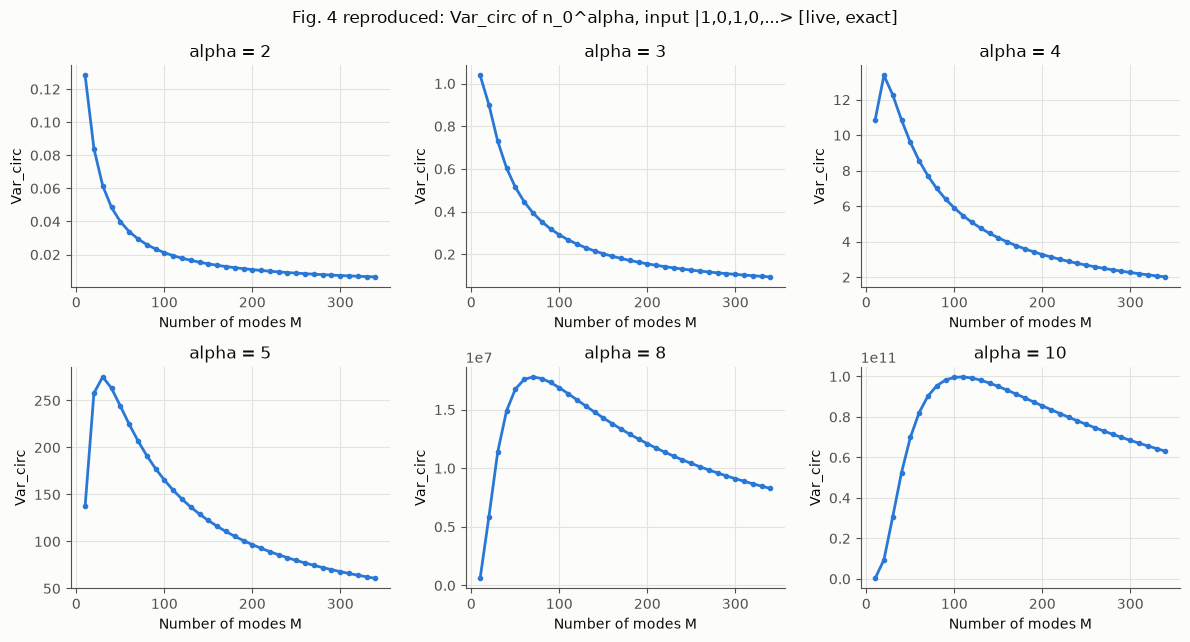

computed in 1.2 s


,alpha,peak M (reproduced),peak Var_circ (reproduced),paper (read from Fig. 4)
0,2,10,1.282581e-01,0.128 at M = 10
1,3,10,1.038148e+00,not read
2,4,20,1.337046e+01,not read
3,5,30,2.750924e+02,not read
4,8,70,1.779184e+07,~1.75e7 at M ~ 70
5,10,110,9.975848e+10,~1.0e11 at M ~ 110


In [9]:
start = time.perf_counter()
occ_of = lambda m: input_occupation(m, "alternating")
fig4 = {a: [float(moments.monomial_variances((a,), occ_of(m))["circuit_variance"]) for m in CONFIG["fig4_modes"]]
        for a in CONFIG["fig4_exponents"]}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for axis, (a, curve) in zip(axes.flat, fig4.items()):
    axis.plot(CONFIG["fig4_modes"], curve, color=SERIES[0], marker="o", markersize=3)
    axis.set_title(f"alpha = {a}")
    axis.set_xlabel("Number of modes M")
    axis.set_ylabel("Var_circ")
fig.suptitle("Fig. 4 reproduced: Var_circ of n_0^alpha, input |1,0,1,0,...> [live, exact]")
fig.tight_layout()
plt.show()
peaks = {a: (CONFIG["fig4_modes"][int(np.argmax(c))], max(c)) for a, c in fig4.items()}
print(f"computed in {time.perf_counter() - start:.1f} s")
pd.DataFrame({
    "alpha": list(peaks),
    "peak M (reproduced)": [p[0] for p in peaks.values()],
    "peak Var_circ (reproduced)": [p[1] for p in peaks.values()],
    # Only the values recorded when Fig. 4 was read (README results table); the others were not read.
    "paper (read from Fig. 4)": ["0.128 at M = 10", "not read", "not read", "not read", "~1.75e7 at M ~ 70", "~1.0e11 at M ~ 110"],
})

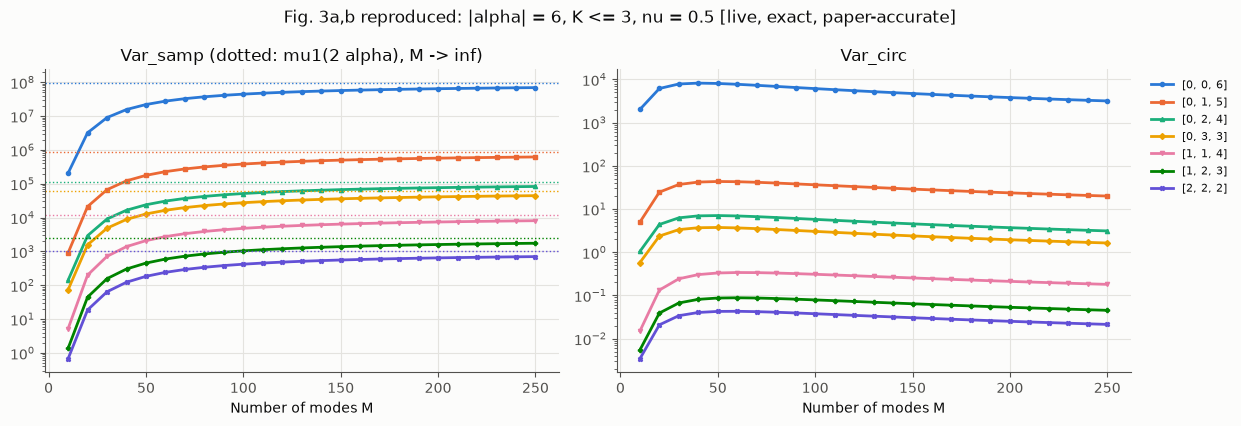

computed in 11.5 s


In [10]:
start = time.perf_counter()
fig3 = {}
for pattern in CONFIG["fig3_patterns"]:
    label = str([0] * (3 - len(pattern)) + pattern)
    recs = [moments.monomial_variances(tuple(pattern), occ_of(m)) for m in CONFIG["fig3_modes"]]
    fig3[label] = {
        "Var_samp": [float(r["sample_variance"]) for r in recs],
        "Var_circ": [float(r["circuit_variance"]) for r in recs],
        "limit": moments.first_moment_limit(tuple(2 * p for p in pattern), 0.5),
    }
fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.3))
for i, (label, data) in enumerate(fig3.items()):
    left.semilogy(CONFIG["fig3_modes"], data["Var_samp"], color=SERIES[i], marker=MARKERS[i], markersize=3, label=label)
    left.axhline(data["limit"], color=SERIES[i], linestyle=":", linewidth=1)
    right.semilogy(CONFIG["fig3_modes"], data["Var_circ"], color=SERIES[i], marker=MARKERS[i], markersize=3, label=label)
left.set_title("Var_samp (dotted: mu1(2 alpha), M -> inf)")
right.set_title("Var_circ")
for axis in (left, right):
    axis.set_xlabel("Number of modes M")
right.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle("Fig. 3a,b reproduced: |alpha| = 6, K <= 3, nu = 0.5 [live, exact, paper-accurate]")
fig.tight_layout()
plt.show()
print(f"computed in {time.perf_counter() - start:.1f} s")

## 7. Headline reproduction result

**7.1 Agreement with the paper's figures.** Values read off the paper's plots against the live computations above and
the stored Fig. 5 runs.

In [11]:
fig5ab = pd.read_csv(RESULTS / "fig5ab_pnp_variance_table.csv")
fig5_pattern = pd.read_csv(RESULTS / "fig5cd_uniform_pattern_table.csv")
m90 = fig5ab[fig5ab.modes == 90]
m60 = fig5_pattern[fig5_pattern.modes == 60]
headline = pd.DataFrame([
    ["Fig. 3b Var_circ [0,0,6], M=250", "~10^3.5 (3162)", fig3["[0, 0, 6]"]["Var_circ"][-1]],
    ["Fig. 3b Var_circ [2,2,2], M=250", "~2e-2", fig3["[2, 2, 2]"]["Var_circ"][-1]],
    ["Fig. 3a Var_samp [0,0,6], M=250", "~1e8", fig3["[0, 0, 6]"]["Var_samp"][-1]],
    ["Fig. 4 Var_circ n^2, M=10", "~0.128", fig4[2][0]],
    ["Fig. 4 Var_circ n^2, M=340", "~0.008", fig4[2][-1]],
    ["Fig. 5a mean Var_samp, M=90 [stored, 20 PNPs]", "~1400", m90.sample_variance.mean()],
    ["Fig. 5b mean Var_circ, M=90 [stored, 20 PNPs]", "~2.5", m90.circuit_variance.mean()],
    ["Fig. 5c mean Var_samp, M=60 [stored, diagnosed scheme]", "~48000", m60.sample_variance.mean()],
    ["Fig. 5d mean Var_circ, M=60 [stored, diagnosed scheme]", "~65", m60.circuit_variance.mean()],
], columns=["item", "paper (read from plot)", "reproduced"])
headline

,item,paper (read from plot),reproduced
0,"Fig. 3b Var_circ [0,0,6], M=250",~10^3.5 (3162),3.174729e+03
1,"Fig. 3b Var_circ [2,2,2], M=250",~2e-2,2.134123e-02
2,"Fig. 3a Var_samp [0,0,6], M=250",~1e8,6.926227e+07
3,"Fig. 4 Var_circ n^2, M=10",~0.128,1.282581e-01
4,"Fig. 4 Var_circ n^2, M=340",~0.008,6.500106e-03
5,"Fig. 5a mean Var_samp, M=90 [stored, 20 PNPs]",~1400,1.403124e+03
6,"Fig. 5b mean Var_circ, M=90 [stored, 20 PNPs]",~2.5,2.534951e+00
7,"Fig. 5c mean Var_samp, M=60 [stored, diagnosed...",~48000,5.619060e+04
8,"Fig. 5d mean Var_circ, M=60 [stored, diagnosed...",~65,7.248703e+01


**7.2 The decay law (C3).** The paper conjectures that the circuit variance of fixed-order PNMs decays polynomially.
On its own range the evidence is ambiguous: a least-squares exponential fits the decaying branch *better* than a power
law. The decisive test is the local slope $d\log\mathrm{Var}_\mathrm{circ}/d\log M$ at much larger $M$ — constant for a
power law, ever more negative for an exponential. **[live, exact; M > 340 is an extension beyond the paper]**

In [12]:
fit = compare_decay_models(CONFIG["fig3_modes"], fig3["[0, 0, 6]"]["Var_circ"], min_points=5)
print(f"Paper range, [0,0,6]: preferred = {fit['preferred']}, AIC(exp) - AIC(power) = {fit['aic_exponential_minus_power_law']:.1f}")
start = time.perf_counter()
slopes = {}
for pattern_name, inp in [("alternating", "alternating"), ("all_ones", "all_ones")]:
    for exps in [(2,), (6,)]:
        curve = [float(moments.monomial_variances(exps, input_occupation(m, inp))["circuit_variance"]) for m in CONFIG["extended_modes"]]
        slopes[(pattern_name, f"n^{exps[0]}")] = [s["slope"] for s in local_loglog_slopes(CONFIG["extended_modes"], curve)]
table = pd.DataFrame(slopes, index=[f"{a}->{b}" for a, b in zip(CONFIG["extended_modes"], CONFIG["extended_modes"][1:])]).T
print(f"computed in {time.perf_counter() - start:.1f} s; local slopes d log Var_circ / d log M:")
table.round(3)

Paper range, [0,0,6]: preferred = exponential, AIC(exp) - AIC(power) = -36.9


computed in 14.4 s; local slopes d log Var_circ / d log M:


250->500  500->1000  1000->2000
alternating n^2    -0.982     -0.991      -0.996
            n^6    -0.874     -0.936      -0.968
all_ones    n^2    -2.977     -2.988      -2.994
            n^6    -2.840     -2.920      -2.960

In [13]:
# Why the exponent differs: the uniform input has no one-body (k = 1) irrep component.
for name in ("alternating", "all_ones"):
    occ = input_occupation(12, name)
    norms = moments.irrep_norms(moments.g_values_fock_state(occ, 3), sum(occ), 12)
    print(f"{name:12s} ||P_k(rho)||^2 for k = 0..3:", [f"{float(x):.2e}" for x in norms])

alternating  ||P_k(rho)||^2 for k = 0..3: ['8.08e-05', '3.50e-04', '1.74e-03', '8.15e-03']
all_ones     ||P_k(rho)||^2 for k = 0..3: ['7.40e-07', '0.00e+00', '3.11e-06', '7.54e-06']


- **Observation:** the local slope settles at $-1$ for the alternating input and $-3$ for the uniform input, with no
  sign of steepening; the uniform input's $k=1$ projection is exactly zero.
- **Inference:** the circuit variance decays as a **power law**, $\sim M^{-1}$ or $\sim M^{-3}$ depending on the
  input's irrep content. The exponential fit on the paper's range is a pre-asymptotic artefact of the turnover after
  the peak. The sample variance tends to the constant $\mu_1(2\alpha)$, so the shot cost grows only polynomially.
- **Remaining uncertainty:** numerical, not a proof; checked for the observables shown and five in the stored
  extension run (`results/extended_*`).
- **Claim impact:** C3 and C4 **reproduced and sharpened** (an input-dependent exponent the paper does not report);
  Figs. 3, 4, 5a,b and 10 reproduce within plot-reading accuracy.

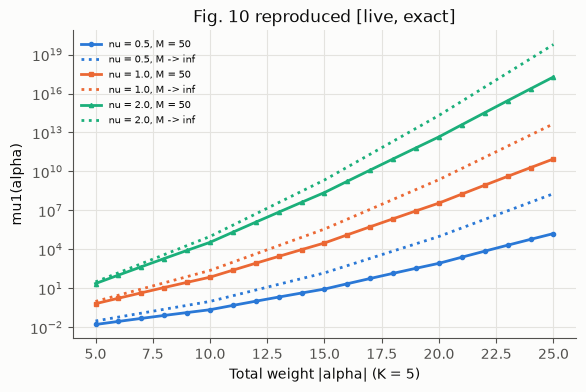

In [14]:
# Fig. 10 (C2): first moment versus total weight at M = 50 and the M -> inf limit [live, exact, paper-accurate].
weights = list(range(5, 26))
fig, axis = plt.subplots(figsize=(6.5, 4))
for i, nu in enumerate([0.5, 1.0, 2.0]):
    split = lambda w: tuple([w // 5 + 1] * (w % 5) + [w // 5] * (5 - w % 5))
    exact = [float(moments.first_moment_exponents(split(w), int(nu * 50), 50)) for w in weights]
    limit = [moments.first_moment_limit(split(w), nu) for w in weights]
    axis.semilogy(weights, exact, color=SERIES[i], marker=MARKERS[i], markersize=3, label=f"nu = {nu}, M = 50")
    axis.semilogy(weights, limit, color=SERIES[i], linestyle=":", label=f"nu = {nu}, M -> inf")
axis.set_xlabel("Total weight |alpha| (K = 5)")
axis.set_ylabel("mu1(alpha)")
axis.set_title("Fig. 10 reproduced [live, exact]")
axis.legend(fontsize=7)
plt.show()

## 8. Fair baseline comparison

### 8.1 Estimation cost (C9): quantum sampling versus classical estimation

The paper's only quantum-versus-classical claim: for balanced-sign fixed-order PNPs with $|A|$ terms, a photonic
device needs $O(|A|)$ shots for additive error $\varepsilon$, while term-wise classical estimation with the Lim-Oh
algorithm needs $O(|A|^2)$ samples. The paper argues this analytically and runs no comparison, so two baselines were
implemented:

- **B1 (the paper's baseline):** Lim-Oh (arXiv:2502.12882, Theorem 1), term by term, with the variance-optimal (Neyman)
  split of samples across terms;
- **B2 (strong conventional baseline):** exact classical evaluation from permanents, since for collision-free inputs
  $\langle a^\dagger_J a_J\rangle=\sum_{|I|=p}|\mathrm{Perm}(U_{I,J})|^2$.

| Fairness dimension | Quantum vs B1 | Quantum vs B2 |
|---|---|---|
| Information and inputs | matched: same $U$, Fock input, polynomial | matched |
| Parameter count | not applicable (estimators) | not applicable |
| Training data | not applicable | not applicable |
| Optimisation steps | not applicable | not applicable |
| Tuning budget | matched: none on either side; Neyman allocation is B1's best case | matched: none |
| Compute and wall time | not matched: B1 time = measured seconds per sample × required samples (projected, CPU); quantum cost is a shot count (no hardware rate assumed) | not matched: B2 is a measured deterministic wall-clock |
| Evaluation protocol | matched: same $\varepsilon$ and $N=\mathrm{Var}/\varepsilon^2$ rule | partially: B2 is exact, so it has no $\varepsilon$ |

The full comparison (M = 16, n = 8, |A| = 10-150, 3 unitaries × 5 polynomial draws, both coefficient families) took
34 s and is **[stored]**. The same code path is first run live at a toy size.

In [15]:
# Live: the identical comparison code at a toy size (M = 6).
smoke_cfg = json.loads((PAPER_DIR / "configs" / "estimator_scaling_smoke.json").read_text())
with tempfile.TemporaryDirectory() as tmp:
    smoke = exp_estimator_scaling.run(smoke_cfg, Path(tmp))
print(f"[live, toy size] Lim-Oh unbiased: {smoke['lim_oh_unbiased']}, B2 max |error| = {smoke['max_b2_abs_error']:.1e}")
print({family: (round(d["slope_quantum_mean"], 2), round(d["slope_lim_oh_mean"], 2)) for family, d in smoke["decisions"].items()},
      "(quantum slope, Lim-Oh slope) at toy size - not evidence")

[live, toy size] Lim-Oh unbiased: True, B2 max |error| = 1.8e-15
{'balanced': (1.43, 2.01), 'positive': (-0.19, 1.83)} (quantum slope, Lim-Oh slope) at toy size - not evidence


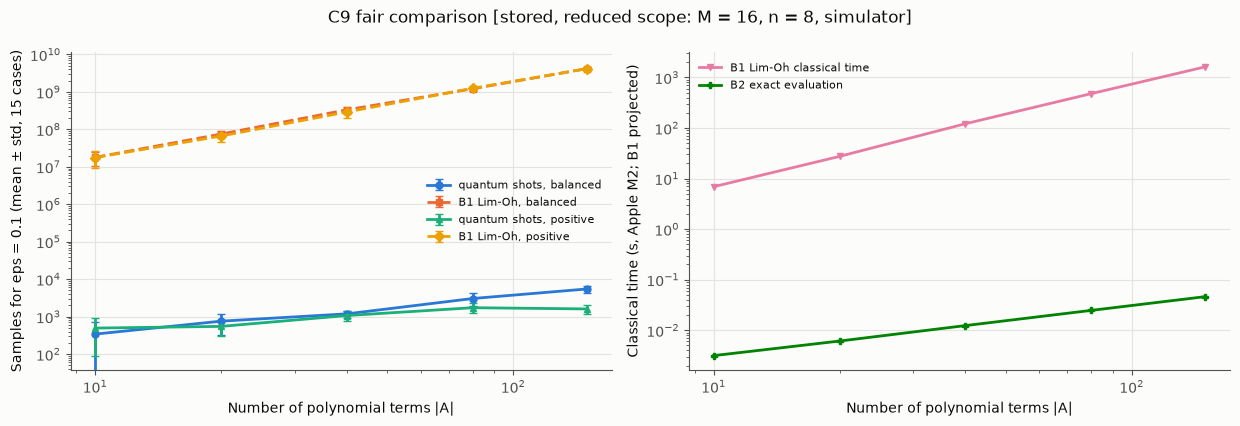

,family,slope_quantum_mean,slope_quantum_std,slope_lim_oh_mean,slope_lim_oh_std,slope_difference_mean,outcome_vs_lim_oh_predeclared_rule
0,balanced,1.073,0.273,2.017,0.068,0.944,SUPPORTED
1,positive,0.535,0.083,2.051,0.119,1.516,SUPPORTED


In [16]:
cases = pd.read_csv(RESULTS / "comparison_c9_cases.csv")
slopes_table = pd.read_csv(RESULTS / "comparison_c9_slopes.csv")
fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.3))
for i, (family, column, style, label) in enumerate([
        ("balanced", "n_quantum", "-", "quantum shots, balanced"), ("balanced", "n_lim_oh", "--", "B1 Lim-Oh, balanced"),
        ("positive", "n_quantum", "-", "quantum shots, positive"), ("positive", "n_lim_oh", "--", "B1 Lim-Oh, positive")]):
    g = cases[cases.family == family].groupby("terms")[column]
    left.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=SERIES[i], marker=MARKERS[i], linestyle=style, capsize=3, label=label)
for i, (column, label) in enumerate([("lim_oh_classical_seconds", "B1 Lim-Oh classical time"), ("b2_exact_seconds", "B2 exact evaluation")]):
    g = cases.groupby("terms")[column].mean()
    right.plot(g.index, g, color=SERIES[4 + i], marker=MARKERS[4 + i], label=label)
for axis in (left, right):
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_xlabel("Number of polynomial terms |A|")
left.set_ylabel("Samples for eps = 0.1 (mean ± std, 15 cases)")
right.set_ylabel("Classical time (s, Apple M2; B1 projected)")
left.legend(fontsize=8)
right.legend(fontsize=8)
fig.suptitle("C9 fair comparison [stored, reduced scope: M = 16, n = 8, simulator]")
fig.tight_layout()
plt.show()
slopes_table[["family", "slope_quantum_mean", "slope_quantum_std", "slope_lim_oh_mean", "slope_lim_oh_std",
              "slope_difference_mean", "outcome_vs_lim_oh_predeclared_rule"]].round(3)

In [17]:
# Individual unitaries (the slope difference is decided per unitary by the predeclared rule).
per_u = []
for (u, family), group in cases.groupby(["unitary", "family"]):
    means = group.groupby("terms")[["n_quantum", "n_lim_oh"]].mean()
    sq = np.polyfit(np.log(means.index), np.log(means.n_quantum), 1)[0]
    sl = np.polyfit(np.log(means.index), np.log(means.n_lim_oh), 1)[0]
    per_u.append({"unitary": u, "family": family, "quantum slope": sq, "Lim-Oh slope": sl, "difference": sl - sq})
print("At |A| = 150: B2 measured", f"{cases[cases.terms == 150].b2_exact_seconds.mean():.3f} s; B1 projected "
      f"{cases[cases.terms == 150].lim_oh_classical_seconds.mean():.0f} s for eps = 0.1")
pd.DataFrame(per_u).round(3)

At |A| = 150: B2 measured 0.046 s; B1 projected 1619 s for eps = 0.1


,unitary,family,quantum slope,Lim-Oh slope,difference
0,0,balanced,1.100,1.971,0.870
1,0,positive,0.442,2.119,1.678
2,1,balanced,0.787,1.987,1.199
3,1,positive,0.599,2.119,1.521
4,2,balanced,1.331,2.095,0.764
5,2,positive,0.565,1.914,1.349


- **Observation:** quantum shots grow as $|A|^{1.07\pm0.27}$ (balanced) against $|A|^{2.02\pm0.07}$ for Lim-Oh, on
  every unitary; positive coefficients grow even more slowly ($|A|^{0.53}$). Exact classical evaluation (B2) returns
  the exact loss in 46 ms at $|A|=150$, against a projected 1,619 s for B1 (measured time per Lim-Oh
  sample × the samples needed for $\varepsilon=0.1$).
- **Inference:** the predicted separation from term-wise Lim-Oh is real, with a large constant (truncated per-term
  norms grow with $n$, contrary to the paper's $O(1)$ assumption). It is **not** caused by sign cancellation: photon
  number conservation already suppresses the variance of positive polynomials. And it is not a speed-up over the
  best classical method for fixed-order polynomials.
- **Remaining uncertainty:** one size ($M=16$, order $\le 2$); marginal-correlator emulators and the regime of NN
  observables with exponentially many expanded terms were not tested.
- **Claim impact:** C9 **partially supported** — scaling versus Lim-Oh supported, stated mechanism contradicted, no
  advantage over exact classical evaluation. No quantum-advantage claim follows.

### 8.2 Training (C11, C12): shot-based gradients against controls

The paper has no comparator for its training demonstrations. The controls planned before any run are: the same rule
with **exact** gradients (upper reference) and an **equal-shot SPSA** estimate (sanity lower reference).

| Fairness dimension | shot GPSR vs exact GPSR | shot GPSR vs SPSA |
|---|---|---|
| Information and inputs | matched: same circuit, observable, initial parameters | matched |
| Parameter count | matched: same circuit | matched |
| Training data | not applicable (fixed observable) | not applicable |
| Optimisation steps | matched: same iterations | matched |
| Tuning budget | matched: one learning rate, selected for exact GPSR on the validation seed | **not matched**: SPSA reuses that rate and a fixed perturbation 0.1, untuned |
| Compute and wall time | shots per iteration matched (exact uses none) | matched shots per iteration |
| Evaluation protocol | matched: exact loss after every iteration | matched |

Live: a toy training run (M = 4) with all three methods. **[live, toy size, 3 seeds]**

In [18]:
live = json.loads((PAPER_DIR / "configs" / "smoke_training.json").read_text())
live.pop("learning_rate_grid"); live.pop("selection_seed")
live.update(CONFIG["live_training"], learning_rate=0.1, device="cpu")
with tempfile.TemporaryDirectory() as tmp:
    start = time.perf_counter()
    toy = exp_training.run(live, Path(tmp))
    elapsed = time.perf_counter() - start
print(f"[live] M = 4, {live['iterations']} iterations, {live['shots']} shots per shifted loss, {elapsed:.1f} s")
pd.DataFrame(toy["results"])[["method", "seed", "initial_exact_loss", "final_exact_loss", "improvement", "fraction_decreasing_steps"]].round(4)

[live] M = 4, 15 iterations, 2000 shots per shifted loss, 0.1 s


,method,seed,initial_exact_loss,final_exact_loss,improvement,fraction_decreasing_steps
0,gpsr_shots,0,0.7309,0.3864,0.3444,1.0
1,gpsr_exact,0,0.7309,0.3924,0.3385,1.0
2,spsa_equal_shots,0,0.7309,0.3589,0.3720,1.0
3,gpsr_shots,1,0.3324,-0.1716,0.5040,1.0
4,gpsr_exact,1,0.3324,-0.1736,0.5060,1.0
5,spsa_equal_shots,1,0.3324,-0.2123,0.5447,1.0
6,gpsr_shots,2,0.2407,0.0092,0.2315,1.0
7,gpsr_exact,2,0.2407,0.0420,0.1987,1.0
8,spsa_equal_shots,2,0.2407,-0.0433,0.2840,1.0


In [19]:
per_seed = pd.read_csv(RESULTS / "training_runs_per_seed.csv")
main_runs = per_seed[per_seed.run.isin(["fig7_m8", "fig7_m12", "fig9_substitute"])]
pivot = main_runs.pivot_table(index=["run", "seed"], columns="method", values="improvement")
display(pivot.round(4))
summary = main_runs.groupby(["run", "method"]).improvement.agg(["mean", "std", "count"]).round(4)
summary

method                gpsr_exact  gpsr_shots  spsa_equal_shots
run             seed                                          
fig7_m12        0         1.7213      1.4134            0.3296
                1         1.7055      1.2174            0.2839
                2         1.6576      1.3173            0.0868
fig7_m8         0         0.0835      0.0834            0.0827
                1         0.1162      0.1157            0.0966
                2         0.2795      0.2809            0.2640
fig9_substitute 0        26.8089     25.5373           -2.8134
                1        33.3628     31.7139           10.3903
                2        34.3634     34.1968            6.7764

mean     std  count
run             method                                  
fig7_m12        gpsr_exact         1.6948  0.0332      3
                gpsr_shots         1.3160  0.0980      3
                spsa_equal_shots   0.2335  0.1290      3
fig7_m8         gpsr_exact         0.1597  0.1050      3
                gpsr_shots         0.1600  0.1059      3
                spsa_equal_shots   0.1478  0.1009      3
fig9_substitute gpsr_exact        31.5117  4.1033      3
                gpsr_shots        30.4827  4.4591      3
                spsa_equal_shots   4.7844  6.8235      3

- **Observation (live, toy size):** at $M=4$ all three methods lower the loss at every step and SPSA is as good
  as GPSR; a 4-mode problem is too easy to separate the methods, so the live run only demonstrates the pipeline.
- **Observation (stored, 3 seeds each):** shot-based GPSR matches exact gradients at $M=8$ on every seed
  (0.160 vs 0.160 mean) and reaches 0.78× at $M=12$ (1.32 vs 1.69); on the 16-mode Fig. 9 substitute it reaches
  0.97× (30.5 vs 31.5). SPSA with equal shots is far behind at $M=12$ (0.23) and on the substitute (4.8), within
  noise at $M=8$.
- **Inference:** the paper's shot budgets are enough for parameter-shift training at these sizes; the claim that such
  circuits *can be trained* holds.
- **Remaining uncertainty:** sizes are reduced (paper: $M=20$ and $26$; PT-2: 48 modes); the SPSA control is untuned,
  so it shows only that the shot budget is used efficiently, not that GPSR is the best optimiser.
- **Claim impact:** C11 **supported at reduced size** (`partial RED-tier`); C12 **partially supported** (simulated
  substitute; hardware not reproduced).

## 9. Controls and ablations

**9.1 Order-growing monomials (C5).** The paper predicts an exponentially growing shot cost for
$\alpha=(1,\dots,1)$ with support $K\propto M$, and states the lower bound
$\mathrm{Var}_\mathrm{samp}\ge(2^K-1)\nu^{2K}$ (Eq. 16). **[live, exact]**

In [20]:
rows = []
for m in [4, 6, 8, 10, 12]:
    for name, nu in [("alternating", 0.5), ("all_twos", 2.0)]:
        occ = input_occupation(m, name)
        k = m // 2
        growing = moments.monomial_variances((1,) * k, occ)
        fixed = moments.monomial_variances((1, 1), occ)
        rows.append({"M": m, "nu": nu, "K": k,
                     "ratio fixed [1,1]": float(fixed["sample_variance"] / fixed["circuit_variance"]),
                     "ratio (1,...,1), K=M/2": float(growing["sample_variance"] / growing["circuit_variance"]),
                     "Var_samp exact": float(growing["sample_variance"]),
                     "Eq. 16 bound": (2**k - 1) * nu ** (2 * k)})
c5 = pd.DataFrame(rows)
c5["bound holds"] = c5["Var_samp exact"] >= c5["Eq. 16 bound"]
c5.round(4)

,M,nu,K,"ratio fixed [1,1]","ratio (1,...,1), K=M/2",Var_samp exact,Eq. 16 bound,bound holds
0,4,0.5,2,9.9038,9.9038,0.0817,0.1875,False
1,4,2.0,2,74.0909,74.0909,13.9714,48.0000,False
2,6,0.5,3,26.2872,49.8498,0.0172,0.1094,False
3,6,2.0,3,329.0000,303.9957,65.5649,448.0000,False
4,8,0.5,4,43.2809,265.4967,0.0030,0.0586,False
5,8,2.0,4,880.6216,1061.9044,269.6322,3840.0000,False
6,10,0.5,5,59.8147,1510.9758,0.0005,0.0303,False
7,10,2.0,5,1841.3214,3232.4886,1050.8463,31744.0000,False
8,12,0.5,6,75.9267,9020.0380,0.0001,0.0154,False
9,12,2.0,6,3323.2278,8883.7419,3993.9296,258048.0000,False


- **Observation:** from $K=2$ to $6$ the order-growing ratio grows ×910 at $\nu=0.5$ (×5-6 per step) and ×120 at
  $\nu=2$, both faster than $2^K$ (×16), while the fixed-order ratio grows ×7.7 at $\nu=0.5$. At $\nu=2$ the
  fixed-order ratio also grows quickly (×45) at these sizes, so the separation is clearest at $\nu=0.5$. The Eq. 16
  bound is violated at every size and density shown.
- **Inference:** the paper's conclusion (exponential cost) holds, but its stated bound does not: it is derived from a
  fixed-$K$, $M\to\infty$ limit that does not apply when $K$ grows with $M$.
- **Remaining uncertainty:** $M\le12$ here ($M\le16$ in the stored run); exponential growth is inferred from few
  points.
- **Claim impact:** C5 conclusion **reproduced** (small sizes); Eq. 16 **contradicted** at tested sizes.

**9.2 Output-probability observables (C7, C8).** Exact projector variances against the paper's Eqs. 21-22, with the
collision probability of Mhiri et al. **[live, exact]**, plus the stored bin study.

In [21]:
from photonic_trainability.lib.exp_output_probability import _projector_case
proj = pd.DataFrame([_projector_case(input_occupation(m, "alternating")) for m in (4, 6, 8)])
display(proj[["modes", "photons", "hilbert_dimension", "variance_ratio", "eq21_matches_exactly", "eq22_matches_exactly",
              "paper_scaling_dim_over_n_plus_n_over_M_plus_1", "mhiri_scaling_dim_over_M_over_n_plus_1"]].round(3))
bins = pd.read_csv(RESULTS / "output_probability_bin_table.csv")
bins.groupby(["case", bins.bin.str.startswith("random")]).circuit_variance_exact.mean().unstack().rename(
    columns={True: "random bins (mean)", False: "structured bin n0>=1"}).round(6)

,modes,photons,hilbert_dimension,variance_ratio,eq21_matches_exactly,eq22_matches_exactly,paper_scaling_dim_over_n_plus_n_over_M_plus_1,mhiri_scaling_dim_over_M_over_n_plus_1
0,4,2,10,9.500,True,True,2.857,3.333
1,6,3,56,42.560,True,True,12.444,18.667
2,8,4,330,207.295,True,True,60.000,110.000


bin,structured bin n0>=1,random bins (mean)
case,,
"M=10, n=5 alternating",0.006549,0.000215
"M=4, n=2 alternating",0.025714,0.024603
"M=6, n=3 alternating",0.013415,0.005870
"M=6, n=3 alternating, K=4",0.013415,0.004066
"M=8, n=2 dilute",0.013749,0.009662
"M=8, n=4 alternating",0.008841,0.001170


- **Observation:** Eqs. 21-22 hold exactly; the projector ratio grows with the Hilbert dimension (9.5 → 207 for
  dimension 10 → 330); the circuit variance of random coarse-grained bins falls from 0.025 at $M=4$ to
  $2\times10^{-4}$ at $M=10$, while the structured bin $n_0\ge1$ stays near $10^{-2}$. The paper's Eq. 23 writes $n/M$ where its source
  gives $M/n$ (both scale exponentially).
- **Remaining uncertainty:** $M\le10$ only; the asymptotic statements rest on the exact formulas.
- **Claim impact:** C7, C8 **reproduced** (small systems).

**9.3 Fig. 5c,d: diagnosing a 150× gap (C6).** The first attempt drew the $5M$ monomials uniformly and came out
150-240× below the paper. With zero-mean coefficients, $\mathbb{E}[\mathrm{Var}(C)]=\mathbb{E}[c^2]\sum_\alpha
\mathrm{Var}(M_\alpha)$ exactly, so each sampling scheme's expected result follows from per-pattern variances.
**[live, exact]** prediction, then **[stored]** confirmation runs (predeclared pass rule: within a factor 1.5 of the
paper at $M=10$ and $60$).

In [22]:
from math import comb, factorial
from collections import Counter
patterns = [(1,), (2,), (1, 1), (3,), (1, 2), (1, 1, 1), (4,), (1, 3), (2, 2), (1, 1, 2), (1, 1, 1, 1)]
def monomial_count(p, m):
    count = comb(m, len(p)) * factorial(len(p))
    for multiplicity in Counter(p).values():
        count //= factorial(multiplicity)
    return count
pred = []
for m in (10, 60):
    occ = input_occupation(m, "alternating")
    per = {p: moments.monomial_variances(p, occ) for p in patterns}
    for scheme, weight in [("uniform over monomials", lambda p: monomial_count(p, m)), ("uniform over patterns", lambda p: 1.0)]:
        w = np.array([weight(p) for p in patterns], dtype=float); w /= w.sum()
        pred.append({"M": m, "scheme": scheme,
                     "E[Var_samp] predicted": 5 * m / 3 * sum(wi * float(per[p]["sample_variance"]) for wi, p in zip(w, patterns)),
                     "E[Var_circ] predicted": 5 * m / 3 * sum(wi * float(per[p]["circuit_variance"]) for wi, p in zip(w, patterns))})
display(pd.DataFrame(pred).round(2))
runs = {name: pd.read_csv(RESULTS / f"fig5cd_{name}_table.csv") for name in ("uniform_monomial", "uniform_pattern", "order_then_partition")}
paper = {10: (1000, 10), 60: (48000, 65)}
pd.DataFrame([{"scheme": name, "M": m, "Var_samp mean": t[t.modes == m].sample_variance.mean(),
               "Var_circ mean": t[t.modes == m].circuit_variance.mean(),
               "factor vs paper (samp, circ)": (round(t[t.modes == m].sample_variance.mean() / paper[m][0], 2),
                                                round(t[t.modes == m].circuit_variance.mean() / paper[m][1], 2))}
              for name, t in runs.items() for m in (10, 60)]).round(2)

,M,scheme,E[Var_samp] predicted,E[Var_circ] predicted
0,10,uniform over monomials,131.62,2.21
1,10,uniform over patterns,1040.47,18.50
2,60,uniform over monomials,277.64,0.22
3,60,uniform over patterns,63622.18,83.83


,scheme,M,Var_samp mean,Var_circ mean,"factor vs paper (samp, circ)"
0,uniform_monomial,10,88.24,1.48,"(0.09, 0.15)"
1,uniform_monomial,60,321.62,0.27,"(0.01, 0.0)"
2,uniform_pattern,10,755.74,13.18,"(0.76, 1.32)"
3,uniform_pattern,60,56190.60,72.49,"(1.17, 1.12)"
4,order_then_partition,10,817.25,14.75,"(0.82, 1.48)"
5,order_then_partition,60,38129.24,50.89,"(0.79, 0.78)"


- **Observation:** uniform-over-monomials almost never draws single-mode powers such as $n^4$ at large $M$, and those
  dominate both variances; drawing exponent patterns uniformly predicts, and the stored runs confirm, the paper's
  magnitudes (factors 0.76-1.48 for both partition-based readings).
- **Inference:** the gap was an unstated term-selection scheme, not a physics or code error (exact values were also
  checked against Monte Carlo on an instance).
- **Remaining uncertainty:** the two partition-based readings cannot be told apart at plot-reading accuracy.
- **Claim impact:** C6 **reproduced** (Fig. 5a,b quantitatively; Fig. 5c,d after diagnosis); the claim holds under
  every scheme — only magnitudes change.

## 10. Robustness and uncertainty

**10.1 Does $N\propto$ ratio really order losses correctly (C1)?** Pairs of Haar circuits, $N$ shots each; success =
the estimated difference has the right sign, for pairs whose true difference exceeds $2\varepsilon\sqrt{
\mathrm{Var}_\mathrm{circ}}$ ($\varepsilon=0.5$). **[stored, 2000 pairs per observable]**

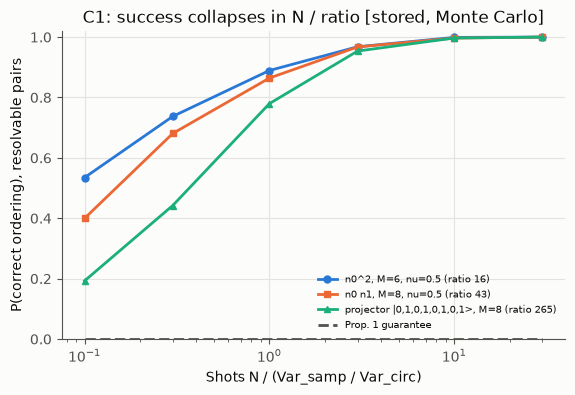

GPSR gradient variance, measured / Eq. 144 prediction: 1.02


In [23]:
ordering = pd.read_csv(RESULTS / "prop1_ordering_table.csv")
prop1 = json.loads((RESULTS / "prop1_metrics.json").read_text())
fig, axis = plt.subplots(figsize=(6.5, 4))
for i, (case, group) in enumerate(ordering.groupby("case", sort=False)):
    axis.semilogx(group.shot_factor, group.success_resolvable_pairs, color=SERIES[i], marker=MARKERS[i],
                  label=f"{case} (ratio {group.variance_ratio.iloc[0]:.0f})")
axis.semilogx(group.shot_factor, group.prop1_guarantee_resolvable, color="#52514e", linestyle="--", label="Prop. 1 guarantee")
axis.set_xlabel("Shots N / (Var_samp / Var_circ)")
axis.set_ylabel("P(correct ordering), resolvable pairs")
axis.set_ylim(0, 1.02)
axis.legend(fontsize=7)
axis.set_title("C1: success collapses in N / ratio [stored, Monte Carlo]")
plt.show()
print("GPSR gradient variance, measured / Eq. 144 prediction:", round(prop1["gradient_variance"]["ratio_measured_to_eq144"], 3))

- **Observation:** three observables with variance ratios 16, 43 and 266 give nearly the same success at a fixed
  multiple of their ratio (0.78-0.89 at $N$ = ratio, 0.95-0.97 at 3×). Prop. 1's explicit guarantee is vacuous at these
  $N$. The measured gradient variance matches Eq. 144 (1.02×).
- **Claim impact:** C1 **supported** as a scaling statement; the explicit bound is loose.

**10.2 Uncertainty and sensitivity of the training results.** Learning rates were chosen by complete, predeclared
sweeps on the validation seed (all candidates shown); the ambiguous "samples per gradient estimate" was run both ways.
**[stored]**

In [24]:
sweeps = pd.read_csv(RESULTS / "lr_selection_summary.csv")
display(sweeps.pivot_table(index="sweep_id", columns="learning_rate", values="final_exact_loss").round(4))
# Predeclared rule: lowest final exact loss of gpsr_exact on validation seed 100; ties -> smaller rate.
recomputed = sweeps.loc[sweeps.groupby("sweep_id").final_exact_loss.idxmin()].set_index("sweep_id").learning_rate
recorded = sweeps[sweeps.selected.astype(str) == "True"].set_index("sweep_id").learning_rate
print("selected rates:", recomputed.to_dict(), "| matches recorded selection:",
      recomputed.sort_index().equals(recorded.sort_index()))
print("seeds used by the sweeps:", sorted(int(x) for x in sweeps.seed.unique()), "(evaluation seeds: 0, 1, 2)")
variants = per_seed[per_seed.run.isin(["fig7_m8", "fig7_m8_pergradient", "fig9_substitute", "fig9_substitute_pergradient"])]
variants.groupby(["run", "method"]).improvement.agg(["mean", "std", "count"]).round(4)

learning_rate,0.01,0.03,0.10,0.30
sweep_id,,,,
lrsel2_fig7_m12,0.0628,0.0470,0.0339,-0.1188
lrsel2_fig7_m8,-0.0305,-0.0360,-1.6625,-1.5684
lrsel2_fig9_m16,-38.9222,-40.1275,-12.0630,4.7699


selected rates: {'lrsel2_fig7_m12': 0.3, 'lrsel2_fig7_m8': 0.1, 'lrsel2_fig9_m16': 0.03} | matches recorded selection: True
seeds used by the sweeps: [100] (evaluation seeds: 0, 1, 2)


mean     std  count
run                         method                                  
fig7_m8                     gpsr_exact         0.1597  0.1050      3
                            gpsr_shots         0.1600  0.1059      3
                            spsa_equal_shots   0.1478  0.1009      3
fig7_m8_pergradient         gpsr_exact         0.1597  0.1050      3
                            gpsr_shots         0.1608  0.1071      3
                            spsa_equal_shots   0.1507  0.1043      3
fig9_substitute             gpsr_exact        31.5117  4.1033      3
                            gpsr_shots        30.4827  4.4591      3
                            spsa_equal_shots   4.7844  6.8235      3
fig9_substitute_pergradient gpsr_exact        31.5117  4.1033      3
                            gpsr_shots        29.2498  6.8901      3
                            spsa_equal_shots   1.5200  2.6295      3

- **Observation:** each sweep has all 4 candidates (complete; no ties); at $M=12$ the largest rate won (grid edge, a
  stated limitation). Reading the shot budget per gradient component (625 and 250 shots per shifted loss) leaves the
  conclusion unchanged.
- **Remaining uncertainty:** 3 seeds per configuration; the spread across seeds is large for the M = 8 problem
  (different random observables), so only within-seed comparisons between methods are meaningful.

## 11. Photonic assessment: does trainability survive realistic hardware?

The paper is natively photonic, and the reproduction already uses MerLin (`QuantumLayer` over the Clements mesh) as
the forward model. The **adaptation** (not part of the reproduction) adds one hardware effect at a time in MerLin:
partial photon distinguishability, uniform loss with or without post-selection, and threshold instead of
photon-number-resolving detection. The predeclared criterion: the variance ratio stays within a factor 3 of ideal,
and its growth from $M=4$ to $8$ within a factor 2. The whole study takes seconds, so it runs live.
**[live, MerLin simulator, reduced scope M ≤ 8]**

[live] 63 estimates in 3.2 s; ideal MerLin vs exact Haar moments: max |z| = 2.21


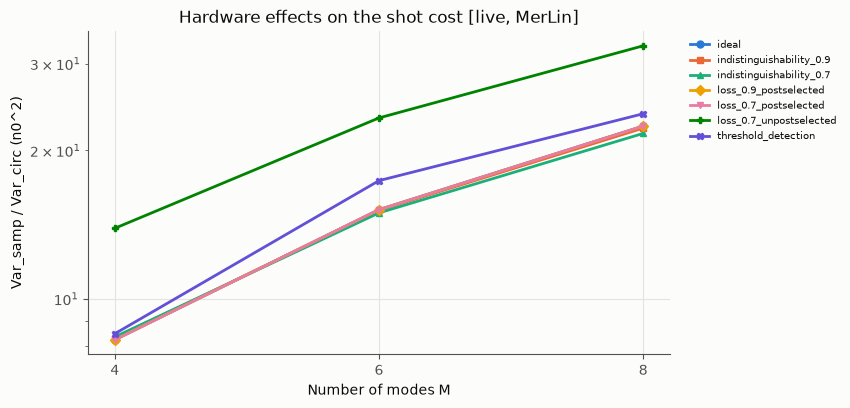

,condition,observable,factor M=4,factor M=6,factor M=8,growth vs ideal,preserves (predeclared)
0,indistinguishability_0.9,n0^2,1.006,0.997,0.991,0.985,True
1,indistinguishability_0.9,n0 n1,1.074,0.999,0.972,0.906,True
2,indistinguishability_0.9,random PNP |alpha|<=2,0.995,1.003,0.997,1.001,True
3,indistinguishability_0.7,n0^2,1.014,0.985,0.966,0.953,True
4,indistinguishability_0.7,n0 n1,1.180,0.975,0.907,0.768,True
5,indistinguishability_0.7,random PNP |alpha|<=2,0.982,1.003,0.985,1.003,True
6,loss_0.9_postselected,n0^2,1.000,1.000,1.000,1.000,True
7,loss_0.9_postselected,n0 n1,1.000,1.000,1.000,1.000,True
8,loss_0.9_postselected,random PNP |alpha|<=2,1.000,1.000,1.000,1.000,True
9,loss_0.7_postselected,n0^2,1.000,1.000,1.000,1.000,True


In [25]:
mcfg = json.loads((PAPER_DIR / "configs" / "merlin_variance_hardware.json").read_text())
mcfg["device"] = "cpu"
with tempfile.TemporaryDirectory() as tmp:
    start = time.perf_counter()
    hw = exp_merlin_variance.run(mcfg, Path(tmp))
    print(f"[live] {len(hw['rows'])} estimates in {time.perf_counter() - start:.1f} s; "
          f"ideal MerLin vs exact Haar moments: max |z| = {hw['ideal_max_abs_z']:.2f}")
hw_rows = pd.DataFrame(hw["rows"])
fig, axis = plt.subplots(figsize=(7.5, 4.2))
for i, (condition, group) in enumerate(hw_rows[hw_rows.observable == "n0^2"].groupby("condition", sort=False)):
    axis.plot(group.modes, group.variance_ratio, color=SERIES[i], marker=MARKERS[i], label=condition)
axis.set_yscale("log")
axis.set_xlabel("Number of modes M")
axis.set_xticks(sorted(hw_rows.modes.unique()))
axis.set_ylabel("Var_samp / Var_circ (n0^2)")
axis.set_title("Hardware effects on the shot cost [live, MerLin]")
axis.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()
pd.DataFrame([{"condition": c["condition"], "observable": c["observable"],
               **{f"factor M={m}": round(f, 3) for m, f in c["ratio_factors_by_modes"].items()},
               "growth vs ideal": round(c["growth_factor_vs_ideal"], 3), "preserves (predeclared)": c["preserves_conclusion"]}
              for c in hw["comparisons"] if c["condition"] != "ideal"])

In [26]:
merlin_runs = per_seed[per_seed.run.str.startswith("merlin_")]
display(merlin_runs.pivot_table(index=["run", "seed"], columns="method", values="improvement").round(4))
ratio = merlin_runs.groupby(["run", "method"]).improvement.mean().unstack()
(ratio.gpsr_shots / ratio.gpsr_exact).rename("shots / exact improvement [stored, M = 6, 3 seeds]").round(3)

method                                gpsr_exact  gpsr_shots
run                             seed                        
merlin_ideal                    0         0.5712      0.5688
                                1         0.0395      0.0395
                                2         1.7374      1.7371
merlin_indistinguishability_0.9 0         0.5436      0.5429
                                1         0.0362      0.0361
                                2         1.5715      1.5665
merlin_loss_0.7_unpostselected  0         0.1772      0.1767
                                1         0.0119      0.0118
                                2         0.6720      0.6713
merlin_threshold_detection      0         0.0655      0.0651
                                1         0.0000      0.0000
                                2         0.0162      0.0161

run
merlin_ideal                       0.999
merlin_indistinguishability_0.9    0.997
merlin_loss_0.7_unpostselected     0.999
merlin_threshold_detection         0.994
Name: shots / exact improvement [stored, M = 6, 3 seeds], dtype: float64

| Hardware-aware field | Value |
|---|---|
| Computation space | `FOCK` (photon-number observables need occupation patterns; source noise needs FOCK) |
| Detector model | PNR; threshold via `pcvl.Detector.threshold()` in one condition |
| Photons / modes | $n=M/2$, $M=4,6,8$ (variance); $n=3$, $M=6$ (training) |
| Input state, encoding | $|1,0,1,0,\dots\rangle$; no data encoding (mesh phases as MerLin `input_parameters`) |
| Post-selection | on $n$ detected photons only in the `*_postselected` loss conditions |
| Simulator / shots | MerLin 0.4.1 CPU, analytic distributions; training shots 10,000 per shifted loss |

- **Observation:** post-selected loss gives exactly the ideal ratio (uniform loss commutes with linear optics; the
  price is the accepted fraction $t^n$); unpost-selected loss raises the ratio 1.4-2.3× but keeps its $M$-dependence;
  distinguishability changes it by ≤ 18%; threshold detection bounds the observable (sample variance drops ~15×) but
  the circuit variance drops by a similar factor, so the ratio barely moves. Shot-based training stays at
  0.994-0.999× of exact gradients under every condition.
- **Inference:** the paper's trainability diagnosis is robust to these imperfections at the sizes tested; bounding
  the observable with threshold detectors does not by itself make training cheaper.
- **Remaining uncertainty:** $M\le8$, representative noise values, simulator only; squeezed-light inputs (PT-2),
  phase noise and pseudo-PNR detection are not modelled. MerLin's `ComputationSpace.UNBUNCHED` is collision-free
  post-selection with renormalisation, not threshold detection, and was not used as such.
- **Photonic verdict:** `MERLIN_IMPLEMENTATION` — meaningful, executed, conclusion preserved (reduced scope).

## 12. Claim-level conclusion

**Separating what was shown.**

| Question | Answer |
|---|---|
| Does the software execute? | Yes — every experiment, the 87 tests, and this notebook. |
| Does the method do what the paper says? | Yes for the variance analysis (exact); yes for training at reduced size. |
| Do the paper's numbers reproduce? | Figs. 3, 4, 5a,b, 10 within plot-reading accuracy; Fig. 5c,d after diagnosing its sampling scheme (§7, §9.3). |
| Does the paper's explanation survive controls? | Mostly: decay law confirmed beyond the paper's range (§7.2); Eq. 16 bound and the sign-cancellation mechanism of C9 do not (§9.1, §8.1). |
| Does the method beat a fair baseline? | Only in sample count against term-wise Lim-Oh; exact classical evaluation is far cheaper for fixed-order observables (§8.1). |

1. **What reproduced.** The exact first and second Haar moments (C2, §4); Figs. 3, 4, 10 at the paper's full range
   and Fig. 5a,b (C3, C4, C6, §6-7); the polynomial decay of the circuit variance, sharpened to $\sim M^{-1}$ and
   $\sim M^{-3}$ (§7.2); the exponential cost of order-growing monomials, projectors and bins (C5, C7, C8, §9.1-9.2);
   the ratio as the scaling variable for shots (C1, §10.1); NN observables as $2^L$-order polynomials (C10, §5);
   shot-based training at the paper's budgets, at reduced size (C11, §8.2).
2. **What did not reproduce.** The Eq. 16 lower bound (violated at tested sizes, §9.1); the sign-cancellation
   mechanism behind C9 (positive coefficients scale better, §8.1); any quantum speed-up over exact classical
   evaluation of fixed-order polynomials (§8.1).
3. **What remains unresolved.** Which partition-based scheme the paper used for Fig. 5c,d (§9.3); C9 against
   marginal-correlator emulators and for NN observables with exponentially many terms (§8.1); Theorem 2 (C13).
4. **What was not attempted.** PT-2 hardware and its squeezed-light input (Fig. 9 is a 16-mode simulated substitute,
   §8.2); Fig. 7 at the paper's 20 and 26 modes (reduced to 8 and 12); Theorem 2's Haar-dialling check.
5. **Reproduction verdict:** **partially reproduced, with high confidence in the reproduced core.** The trainability
   theory and its figures reproduce quantitatively; the training demonstrations reproduce qualitatively at reduced
   scale; the classical-comparison claim is only partially supported.
6. **Extension and photonic verdict:** the decay-law extension supports and sharpens the paper's conjecture (§7.2);
   the MerLin hardware adaptation shows the trainability conclusion survives partial distinguishability, loss and
   threshold detection at $M\le8$ (§11). No quantum advantage follows from any result in this notebook.

**Limitations** (also in the README): reduced training sizes and a simulated hardware substitute; two unstated details
resolved by diagnosis (Fig. 5c,d scheme, $\nu=1$ input of Fig. 3c,d); small systems for E6, E7, E10; representative
noise values at $M\le8$; C9 tested at one size; an untuned SPSA control; a learning rate at the edge of its grid for
$M=12$.

In [27]:
print(f"notebook live computation time: {time.perf_counter() - NOTEBOOK_STARTED:.0f} s")

notebook live computation time: 37 s
